In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv(r"D:\Projects\dataest-project/dataset.csv")

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [6]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Order Date']= pd.to_datetime(df['Order Date'])

In [9]:
df['Ship Date']=pd.to_datetime(df['Ship Date'])

In [10]:
df['shipment_days']= df['Ship Date']-df['Order Date']

In [11]:
df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum().sort_values(ascending=False)

Order Date
2017-11    118447.8250
2016-12     96999.0430
2017-09     87866.6520
2017-12     83829.3188
2014-09     81777.3508
2016-11     79411.9658
2014-11     78628.7167
2017-10     77776.9232
2015-11     75972.5635
2015-12     74919.5212
2016-09     73410.0249
2014-12     69545.6205
2015-09     64595.9180
2017-08     63120.8880
2016-10     59687.7450
2017-03     58872.3528
2016-05     56987.7280
2014-03     55691.0090
2017-06     52981.7257
2016-03     51715.8750
2017-07     45264.4160
2017-05     44261.1102
2017-01     43971.3740
2016-06     40344.5340
2016-07     39261.9630
2016-04     38750.0390
2015-03     38726.2520
2015-08     36898.3322
2017-04     36521.5361
2014-06     34595.1276
2015-04     34195.2085
2014-07     33946.3930
2014-10     31453.3930
2015-10     31404.9235
2016-08     31115.3743
2015-05     30131.6865
2015-07     28765.3250
2014-04     28295.3450
2014-08     27909.4685
2015-06     24797.2920
2014-05     23648.2870
2016-02     22978.8150
2017-02     20301.1334


In [12]:
def profit_by(df, group_col):
    result=df.groupby(group_col).agg(
        total_sales=('Sales','sum'),
        total_profit=('Profit', 'sum'),
        order_count= ('Order ID', 'count')
    ).reset_index()

    result['profit_margin']=(result['total_profit']/result['total_sales']*100).round(2)
    result['avg_order_value']=(result['total_sales']/result['order_count']).round(2)

    return result.sort_values('total_profit', ascending= False)

In [13]:
profit_by(df,'Category')

,Category,total_sales,total_profit,order_count,profit_margin,avg_order_value
2,Technology,836154.0330,145454.9481,1847,17.40,452.71
1,Office Supplies,719047.0320,122490.8008,6026,17.04,119.32
0,Furniture,741999.7953,18451.2728,2121,2.49,349.83


In [14]:
profit_by(df, 'Sub-Category')

,Sub-Category,total_sales,total_profit,order_count,profit_margin,avg_order_value
6,Copiers,149528.0300,55617.8249,68,37.20,2198.94
13,Phones,330007.0540,44515.7306,889,13.49,371.21
0,Accessories,167380.3180,41936.6357,775,25.05,215.97
12,Paper,78479.2060,34053.5693,1370,43.39,57.28
3,Binders,203412.7330,30221.7633,1523,14.86,133.56
5,Chairs,328449.1030,26590.1663,617,8.10,532.33
14,Storage,223843.6080,21278.8264,846,9.51,264.59
1,Appliances,107532.1610,18138.0054,466,16.87,230.76
9,Furnishings,91705.1640,13059.1436,957,14.24,95.83
7,Envelopes,16476.4020,6964.1767,254,42.27,64.87


In [15]:
(df.groupby('Discount')['Profit'].sum()/df.groupby('Discount')['Sales'].sum()*100).round(2)

Discount
0.00     29.51
0.10     16.61
0.15      5.15
0.20     11.82
0.30    -10.05
0.32    -16.50
0.40    -19.81
0.45    -45.45
0.50    -34.80
0.60    -89.46
0.70    -98.66
0.80   -180.03
dtype: float64

In [16]:
def discount_impact(df, group_col):
    result=df.groupby(group_col).agg(
        total_sales=('Sales', 'sum'),
        total_profit=('Profit', 'sum'),
        order_count=('Order ID', 'count'),
        avg_discount=('Discount', 'mean')
    ).reset_index()



    result['profit_margin']=(result['total_profit']/result['total_sales']*100).round(2)
    result['discount_to_margin_ratio']=(result['avg_discount']/result['profit_margin']*100).round(2)


    return result.sort_values('avg_discount', ascending=False)

In [17]:
discount_impact(df,'Segment')

,Segment,total_sales,total_profit,order_count,avg_discount,profit_margin,discount_to_margin_ratio
1,Corporate,7.061464e+05,91979.1340,3020,0.158228,13.03,1.21
0,Consumer,1.161401e+06,134119.2092,5191,0.158141,11.55,1.37
2,Home Office,4.296531e+05,60298.6785,1783,0.147128,14.03,1.05


In [18]:
discount_impact(df,'Category')

,Category,total_sales,total_profit,order_count,avg_discount,profit_margin,discount_to_margin_ratio
0,Furniture,741999.7953,18451.2728,2121,0.173923,2.49,6.98
1,Office Supplies,719047.0320,122490.8008,6026,0.157285,17.04,0.92
2,Technology,836154.0330,145454.9481,1847,0.132323,17.40,0.76


In [19]:
discount_impact(df,'Sub-Category')

,Sub-Category,total_sales,total_profit,order_count,avg_discount,profit_margin,discount_to_margin_ratio
3,Binders,203412.7330,30221.7633,1523,0.372292,14.86,2.51
11,Machines,189238.6310,3384.7569,115,0.306087,1.79,17.10
16,Tables,206965.5320,-17725.4811,319,0.261285,-8.56,-3.05
4,Bookcases,114879.9963,-3472.5560,228,0.211140,-3.02,-6.99
5,Chairs,328449.1030,26590.1663,617,0.170178,8.10,2.10
1,Appliances,107532.1610,18138.0054,466,0.166524,16.87,0.99
6,Copiers,149528.0300,55617.8249,68,0.161765,37.20,0.43
13,Phones,330007.0540,44515.7306,889,0.154556,13.49,1.15
9,Furnishings,91705.1640,13059.1436,957,0.138349,14.24,0.97
8,Fasteners,3024.2800,949.5182,217,0.082028,31.40,0.26


In [20]:
profit_by(df, 'State')

,State,total_sales,total_profit,order_count,profit_margin,avg_order_value
3,California,457687.6315,76381.3871,2001,16.69,228.73
30,New York,310876.2710,74038.5486,1128,23.82,275.60
45,Washington,138641.2700,33402.6517,506,24.09,273.99
20,Michigan,76269.6140,24463.1876,255,32.07,299.10
44,Virginia,70636.7200,18597.9504,224,26.33,315.34
12,Indiana,53555.3600,18382.9363,149,34.33,359.43
9,Georgia,49095.8400,16250.0433,184,33.10,266.83
15,Kentucky,36591.7500,11199.6966,139,30.61,263.25
21,Minnesota,29863.1500,10823.1874,89,36.24,335.54
6,Delaware,27451.0690,9977.3748,96,36.35,285.95


In [21]:
def state_profibility(df):
    results=profit_by(df,'State')
    results['regins']=df.groupby('State')['Region'].first().values
    results['pct_order_at_lose']=df.groupby('State')['Profit'].apply(
        lambda  x:(x<0).sum()/len(x)*100
    ).round(2).values
    return  results[results['total_profit']<10]

In [22]:
state_profibility(df)

,State,total_sales,total_profit,order_count,profit_margin,avg_order_value,regins,pct_order_at_lose
35,Oregon,17431.1500,-1190.4705,124,-6.83,140.57,Central,0.00
8,Florida,89473.7080,-3399.3017,383,-3.80,233.61,South,35.52
1,Arizona,35282.0010,-3427.9246,224,-9.72,157.51,Central,49.34
40,Tennessee,30661.8730,-5341.6936,183,-17.42,167.55,West,0.00
4,Colorado,32108.1180,-6527.8579,182,-20.33,176.42,East,0.00
31,North Carolina,55603.1640,-7490.9122,249,-13.47,223.31,South,0.00
11,Illinois,80166.1010,-12607.8870,492,-15.73,162.94,West,3.36
36,Pennsylvania,116511.9140,-15559.9603,587,-13.35,198.49,East,25.00
33,Ohio,78258.1360,-16971.3766,469,-21.69,166.86,Central,0.00
41,Texas,170188.0458,-25729.3563,985,-15.12,172.78,West,0.00


In [23]:
def top_customer(df, topn=10):
    top_customers=df.groupby('Customer ID').agg(
      customer_name=('Customer Name', 'first'),
      total_sales = ('Sales', 'sum'),
      total_profit = ('Profit', 'sum'),
      order_count = ('Order ID', 'count'),  
      segment=('Segment', 'first'),
      region=('Region', 'first')
    ).reset_index()

    top_customers['avg_order_value']=top_customers['total_sales']/top_customers['order_count']
    top_customers['profit_margin']=(top_customers['total_profit']/top_customers['total_sales']*100).round(2)

    return top_customers.nlargest(topn,'total_profit')

In [24]:
top_customer(df)

,Customer ID,customer_name,total_sales,total_profit,order_count,segment,region,avg_order_value,profit_margin
741,TC-20980,Tamara Chand,19052.218,8981.3239,12,Corporate,West,1587.684833,47.14
621,RB-19360,Raymond Buch,15117.339,6976.0959,18,Consumer,East,839.852167,46.15
669,SC-20095,Sanjit Chand,14142.334,5757.4119,22,Consumer,West,642.833364,40.71
327,HL-15040,Hunter Lopez,12873.298,5622.4292,11,Consumer,Central,1170.299818,43.68
6,AB-10105,Adrian Barton,14473.571,5444.8055,20,Consumer,West,723.678550,37.62
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,10,Home Office,East,1459.562000,32.23
160,CM-12385,Christopher Martinez,8954.020,3899.8904,10,Consumer,South,895.402000,43.55
424,KD-16495,Keith Dawkins,8181.256,3038.6254,28,Corporate,East,292.187714,37.14
48,AR-10540,Andy Reiter,6608.448,2884.6208,9,Consumer,East,734.272000,43.65
234,DR-12940,Daniel Raglin,8350.868,2869.0760,13,Home Office,East,642.374462,34.36


In [25]:
def top_customer_purchase(df, CustomerID):
    customer= df[df['Customer ID']==CustomerID]
    purchase= (customer.groupby('Sub-Category').agg(
       quantity = ('Quantity','sum'),
        total_sale = ('Sales', 'sum'),
        total_profit = ('Profit', 'sum'),
        order_count = ('Order ID', 'nunique'),
        avg_discount = ('Discount', 'mean') 
    )).reset_index()

    purchase['profit_margin']=(purchase['total_profit']/purchase['total_sale']*100).round(2)
    return  purchase.sort_values('total_profit', ascending = False)

In [26]:
top_customer_purchase(df, 'TA-21385')

,Sub-Category,quantity,total_sale,total_profit,order_count,avg_discount,profit_margin
3,Copiers,4,11199.968,3919.9888,1,0.2,35.00
6,Phones,9,2452.590,648.4219,1,0.0,26.44
2,Binders,2,331.960,149.3820,1,0.0,45.00
4,Envelopes,5,63.900,28.7550,1,0.0,45.00
0,Accessories,5,57.400,10.9060,1,0.0,19.00
7,Supplies,3,357.930,7.1586,1,0.0,2.00
1,Art,4,7.040,2.0416,1,0.0,29.00
5,Furnishings,4,124.832,-62.8656,2,0.3,-50.36


<Axes: xlabel='Order Date', ylabel='total_profit'>

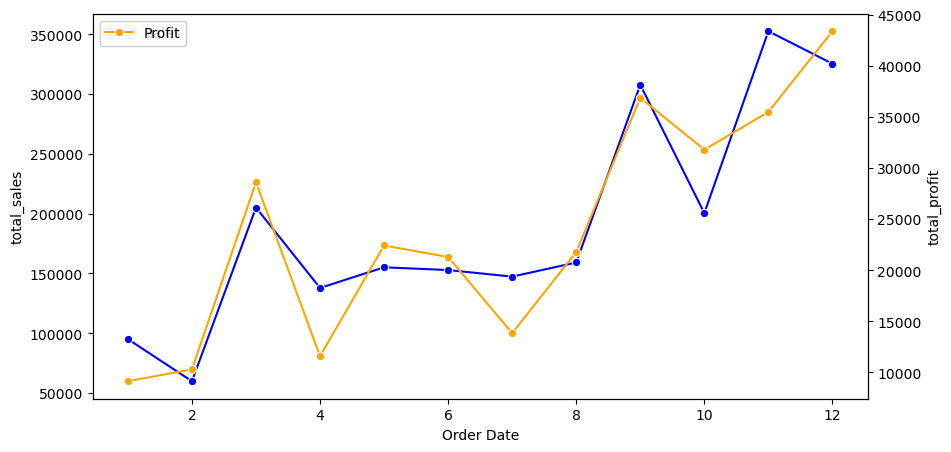

In [27]:
monthly=df.groupby(df['Order Date'].dt.month).agg(
    total_sales=('Sales', 'sum'),
    total_profit=('Profit','sum')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10,5))
sns.lineplot(data=monthly, x='Order Date', y='total_sales', ax=ax1, marker='o', label='Sales', color='blue')
ax2=ax1.twinx()
sns.lineplot(data=monthly, x='Order Date', y='total_profit', ax=ax2, marker='o', label='Profit', color='orange')

C:\Users\scc\AppData\Local\Temp\ipykernel_14888\100828812.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub_cat, x='total_profit', y='Sub-Category', palette=colors)


<Axes: xlabel='total_profit', ylabel='Sub-Category'>

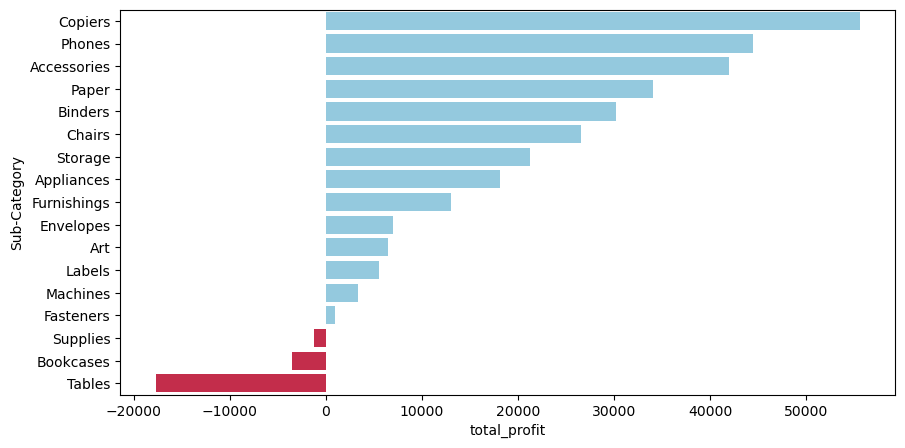

In [28]:
sub_cat= profit_by(df, 'Sub-Category')

plt.figure(figsize=(10,5))

colors=['crimson' if x<0 else "skyblue" for x in sub_cat['total_profit']]

sns.barplot(data=sub_cat, x='total_profit', y='Sub-Category', palette=colors)


Text(0.5, 1.0, 'Discount Level vs Profit')

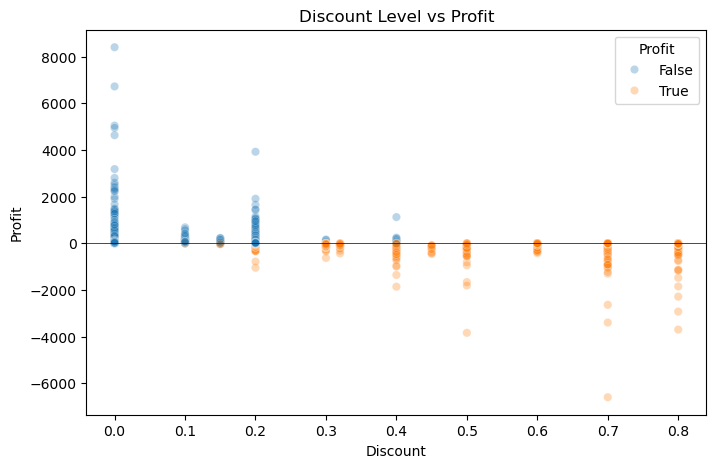

In [29]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.3, hue=(df['Profit']<0))

plt.axhline(0, color='black', linewidth=.5)

plt.title('Discount Level vs Profit')


Text(0.5, 1.0, 'Avg Discount by Category')

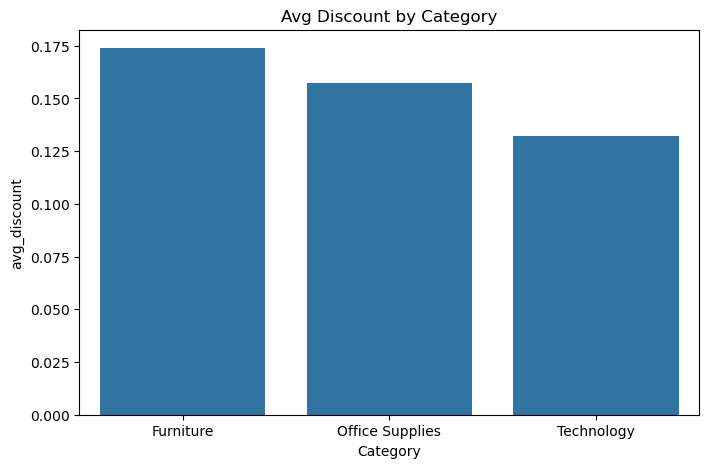

In [30]:
plt.figure(figsize=(8,5))

sns.barplot(data=discount_impact(df, 'Category'), x='Category', y='avg_discount' )

plt.title('Avg Discount by Category')

Text(0.5, 1.0, 'States Operating at a Loss')

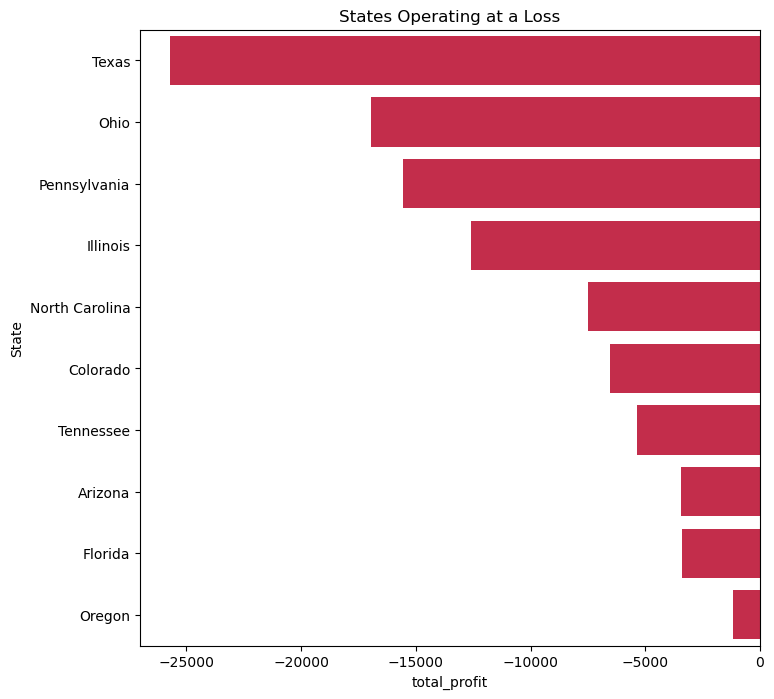

In [31]:
losing= state_profibility(df).sort_values('total_profit')

plt.figure(figsize=(8,8))

sns.barplot(data=losing, x='total_profit', y='State', color='crimson')

plt.title('States Operating at a Loss')

C:\Users\scc\AppData\Local\Temp\ipykernel_14888\2439298033.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='total_profit', y='customer_name', palette='viridis')


Text(0.5, 1.0, 'Top 10 Customers by Profit')

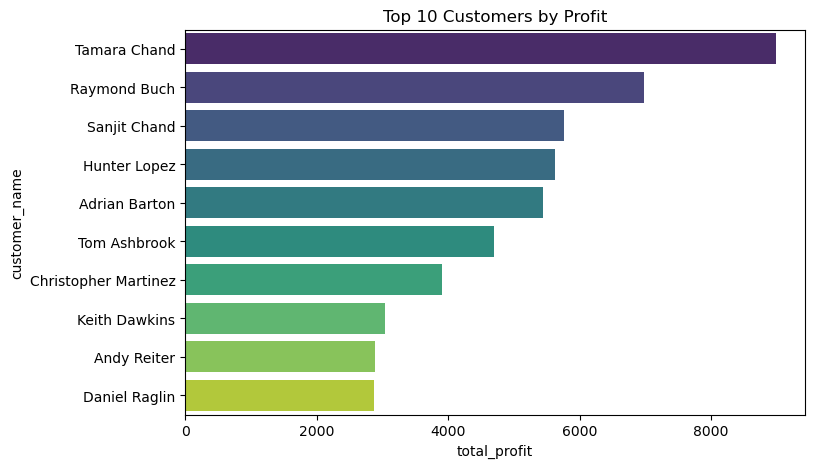

In [32]:
top10= top_customer(df)

plt.figure(figsize=(8,5))

sns.barplot(data=top10, x='total_profit', y='customer_name', palette='viridis')

plt.title('Top 10 Customers by Profit')

Text(0.5, 1.0, 'Average Shipment Days by Region and Ship Mode')

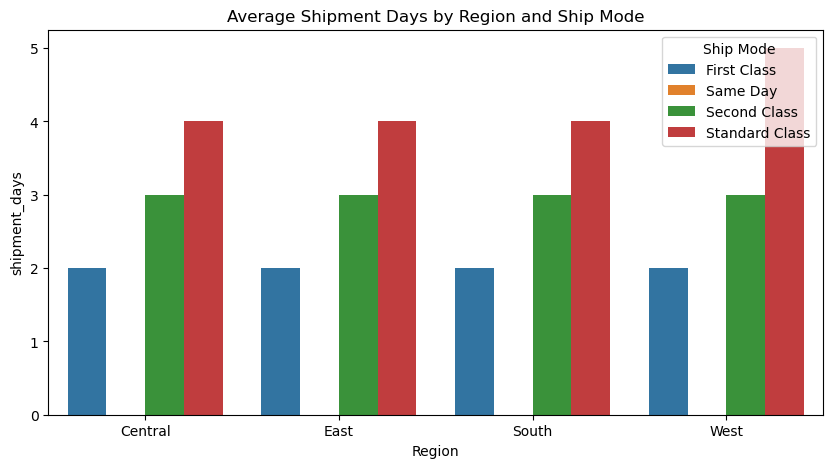

In [33]:
ship_data=df.groupby(['Region', 'Ship Mode'])['shipment_days'].mean().dt.days.reset_index()

plt.figure(figsize=(10,5))
sns.barplot(data=ship_data, x='Region', y='shipment_days', hue='Ship Mode')

plt.title('Average Shipment Days by Region and Ship Mode')

In [34]:
ship_data=df.groupby(['Region', 'Ship Mode'])['shipment_days'].mean().dt.days.reset_index()
ship_data

,Region,Ship Mode,shipment_days
0,Central,First Class,2
1,Central,Same Day,0
2,Central,Second Class,3
3,Central,Standard Class,4
4,East,First Class,2
5,East,Same Day,0
6,East,Second Class,3
7,East,Standard Class,4
8,South,First Class,2
9,South,Same Day,0
